# 🚀 Practice Day 50

**📅 Date:** **2026-11-02**  
**📁 Category:** **Phase 2 · SQL 중급(JOIN·서브쿼리·CASE WHEN) (Round 4/5)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice JOIN, a subquery, and CASE WHEN in DuckDB SQL — the same clinic data as yesterday, solved a different way
  (DuckDB SQL의 JOIN·서브쿼리·CASE WHEN 연습 — 어제와 같은 클리닉 데이터를 다른 방식으로 풀어보기)
- Find which specialty reaches the most patients, which patients visit more than average, and how appointment costs break into tiers
  (어떤 진료과목이 가장 많은 환자에게 도달하는지, 평균보다 자주 방문하는 환자는 누구인지, 진료비가 구간별로 어떻게 나뉘는지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Meadowbrook Clinic — same 3 tables as Day 49, solved with SQL this time / Meadowbrook Clinic — 환자·의사·진료예약 (Day 49와 동일 데이터, SQL로 재풀이)

**Source:** Synthetically generated for practice, same generation code as Day 49 / 실습을 위해 코드로 생성, Day 49와 동일한 생성 코드

**Description:** The same `patients` (65), `doctors` (8), and `appointments` (320) tables from yesterday's file. Costs are in USD. This time, instead of pandas merge, the focus is on answering similar questions using DuckDB SQL — JOIN across all three tables, a subquery, and CASE WHEN.
(어제(Day 49) 만든 것과 동일한 patients(65)·doctors(8)·appointments(320) 3테이블입니다. 진료비는 USD입니다. 이번에는 pandas merge 대신 duckdb.sql()의 JOIN(3테이블 전체 연결), 서브쿼리, CASE WHEN을 사용해 비슷한 질문에 답하는 데 초점을 둡니다.)

## Dataset Preview

In [50]:
# Dataset Preview
import pandas as pd
import numpy as np
from IPython.display import display

np.random.seed(42)
rng = np.random.default_rng(42)

# --- patients ---
first_names = ['Sarah','James','Maria','David','Emily','Michael','Laura','Kevin','Anna','Brian',
               'Nicole','Daniel','Rachel','Peter','Grace','Tom','Julia','Mark','Susan','Chris',
               'Olivia','Ethan','Sophia','Lucas','Isabella','Mason','Ava','Logan','Mia','Noah']
last_names = ['Kim','Park','Lee','Smith','Johnson','Garcia','Brown','Davis','Wilson','Martinez',
              'Taylor','Clark','Lewis','Walker','Hall']

n_patients = 65
rng2 = np.random.default_rng(11)
patient_names = []
used = set()
while len(patient_names) < n_patients:
    name = f"{rng2.choice(first_names)} {rng2.choice(last_names)}"
    if name not in used:
        used.add(name)
        patient_names.append(name)

surname_map = {'Kim': 'Bennett', 'Park': 'Cooper', 'Lee': 'Hughes'}
patient_names = [
    f"{first} {surname_map.get(last, last)}"
    for first, last in (name.split(' ', 1) for name in patient_names)
]

patients = pd.DataFrame({
    'patient_id': [f'P{str(i).zfill(3)}' for i in range(1, n_patients + 1)],
    'patient_name': patient_names
})

# --- doctors ---
doctors_data = [
    ('Dr. Alina Novak', 'General Practice'),
    ('Dr. Ben Ortiz', 'General Practice'),
    ('Dr. Priya Nair', 'Pediatrics'),
    ('Dr. Samuel Chen', 'Pediatrics'),
    ('Dr. Elena Petrova', 'Cardiology'),
    ('Dr. Marcus Webb', 'Dermatology'),
    ('Dr. Fatima Haddad', 'Orthopedics'),
    ('Dr. Owen Fischer', 'Orthopedics'),
]
doctors = pd.DataFrame(doctors_data, columns=['doctor_name', 'specialty'])
doctors.insert(0, 'doctor_id', [f'D{str(i).zfill(2)}' for i in range(1, len(doctors) + 1)])

specialty_cost = {'General Practice': 45, 'Pediatrics': 55, 'Cardiology': 120,
                   'Dermatology': 80, 'Orthopedics': 95}  # USD

# --- appointments (some doctors/patients seen far more often than others) ---
n_appointments = 320
doctor_ids = doctors['doctor_id'].values
doctor_weight = rng.gamma(shape=2.0, scale=1.0, size=len(doctors))
doctor_p = doctor_weight / doctor_weight.sum()

patient_weight = rng.gamma(shape=1.6, scale=1.0, size=n_patients)
patient_p = patient_weight / patient_weight.sum()

appt_doctor = rng.choice(doctor_ids, size=n_appointments, p=doctor_p)
appt_patient = rng.choice(patients['patient_id'].values, size=n_appointments, p=patient_p)
appt_dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(rng.integers(0, 210, size=n_appointments), unit='D')

doc_specialty_map = dict(zip(doctors['doctor_id'], doctors['specialty']))
rows = []
for i in range(n_appointments):
    did = appt_doctor[i]
    spec = doc_specialty_map[did]
    cost_noise = rng.normal(1.0, 0.08)
    cost = int(round(specialty_cost[spec] * cost_noise))  # nearest USD
    rows.append({'appointment_id': f'A{str(i+1).zfill(4)}', 'patient_id': appt_patient[i],
                 'doctor_id': did, 'appointment_date': appt_dates[i], 'cost': cost})
appointments = pd.DataFrame(rows).sort_values('appointment_date').reset_index(drop=True)

print("Patients:")
display(patients.head())
print("\nDoctors:")
display(doctors)
print("\nAppointments:")
display(appointments.head())


Patients:


,patient_id,patient_name
0,P001,Emily Cooper
1,P002,Lucas Davis
2,P003,Mark Martinez
3,P004,Ethan Bennett
4,P005,Grace Hughes



Doctors:


,doctor_id,doctor_name,specialty
0,D01,Dr. Alina Novak,General Practice
1,D02,Dr. Ben Ortiz,General Practice
2,D03,Dr. Priya Nair,Pediatrics
3,D04,Dr. Samuel Chen,Pediatrics
4,D05,Dr. Elena Petrova,Cardiology
5,D06,Dr. Marcus Webb,Dermatology
6,D07,Dr. Fatima Haddad,Orthopedics
7,D08,Dr. Owen Fischer,Orthopedics



Appointments:


,appointment_id,patient_id,doctor_id,appointment_date,cost
0,A0042,P055,D02,2024-01-01,45
1,A0159,P037,D02,2024-01-01,46
2,A0227,P051,D08,2024-01-02,91
3,A0183,P048,D06,2024-01-03,88
4,A0102,P055,D07,2024-01-03,92


## Dataset Information

In [51]:
# Dataset Information
print("Patients:", patients.shape)
patients.info()
print("\nDoctors:", doctors.shape)
doctors.info()
print("\nAppointments:", appointments.shape)
appointments.info()

print("\n--- Describe: Patients ---")
display(patients.describe(include='all'))
print("\n--- Describe: Doctors ---")
display(doctors.describe(include='all'))
print("\n--- Describe: Appointments ---")
display(appointments.describe(include='all'))


Patients: (65, 2)
<class 'pandas.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   patient_id    65 non-null     str  
 1   patient_name  65 non-null     str  
dtypes: str(2)
memory usage: 1.1 KB

Doctors: (8, 3)
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   doctor_id    8 non-null      str  
 1   doctor_name  8 non-null      str  
 2   specialty    8 non-null      str  
dtypes: str(3)
memory usage: 324.0 bytes

Appointments: (320, 5)
<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   appointment_id    320 non-null    str           
 1   patient_id        320 non-null    str           
 2   doctor

,patient_id,patient_name
count,65,65
unique,65,65
top,P001,Emily Cooper
freq,1,1



--- Describe: Doctors ---


,doctor_id,doctor_name,specialty
count,8,8,8
unique,8,8,5
top,D01,Dr. Alina Novak,General Practice
freq,1,1,2



--- Describe: Appointments ---


,appointment_id,patient_id,doctor_id,appointment_date,cost
count,320,320,320,320,320.000000
unique,320,59,8,NaN,NaN
top,A0042,P061,D02,NaN,NaN
freq,1,15,57,NaN,NaN
mean,NaN,NaN,NaN,2024-04-11 22:39:00,76.271875
min,NaN,NaN,NaN,2024-01-01 00:00:00,36.000000
25%,NaN,NaN,NaN,2024-02-18 00:00:00,48.000000
50%,NaN,NaN,NaN,2024-04-09 12:00:00,79.500000
75%,NaN,NaN,NaN,2024-06-04 00:00:00,98.000000
max,NaN,NaN,NaN,2024-07-27 00:00:00,147.000000


---
# ❓ Business Questions

1. **(Analysis — JOIN)** Joining all three tables, how many unique patients does each specialty reach through its doctors?
   (3개 테이블을 JOIN했을 때, 각 진료과목은 몇 명의 고유 환자에게 도달하는가?)
2. **(Analysis — Subquery)** Using a subquery to find the average number of visits per patient, which patients visited more often than that average?
   (서브쿼리로 환자 1명당 평균 방문 횟수를 구했을 때, 그 평균보다 더 자주 방문한 환자는?)
3. **(Analysis — CASE WHEN)** Using CASE WHEN to bucket each appointment's cost into Low (<60)/Medium (60-100)/High (>100) tiers, how many appointments fall into each tier?
   (CASE WHEN으로 진료비를 저($60 미만)/중($60~$100)/고($100 초과) 구간으로 나누면, 구간별 건수는?)
4. **(Visualization)** Compare how many unique patients each specialty reaches.
   (진료과목별 고유 환자 도달 수를 비교하면?)
5. **(Visualization)** Compare appointment counts across the three cost tiers.
   (3개 비용 구간별 진료건수를 비교하면?)

---
# 🔍 Data Cleaning Check


In [52]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("===== patients =====")
print("Missing values")
print(patients.isnull().sum())
print("\nDuplicate rows:", patients.duplicated().sum())
print("\nDtypes")
print(patients.dtypes)
print("\nColumn names")
print(patients.columns.tolist())
obj_cols = patients.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(patients[obj_cols].nunique())
print()

print("===== doctors =====")
print("Missing values")
print(doctors.isnull().sum())
print("\nDuplicate rows:", doctors.duplicated().sum())
print("\nDtypes")
print(doctors.dtypes)
print("\nColumn names")
print(doctors.columns.tolist())
obj_cols = doctors.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(doctors[obj_cols].nunique())
print()

print("===== appointments =====")
print("Missing values")
print(appointments.isnull().sum())
print("\nDuplicate rows:", appointments.duplicated().sum())
print("\nDtypes")
print(appointments.dtypes)
print("\nColumn names")
print(appointments.columns.tolist())
obj_cols = appointments.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(appointments[obj_cols].nunique())
print()


===== patients =====
Missing values
patient_id      0
patient_name    0
dtype: int64

Duplicate rows: 0

Dtypes
patient_id      str
patient_name    str
dtype: object

Column names
['patient_id', 'patient_name']

Text columns — unique counts
patient_id      65
patient_name    65
dtype: int64

===== doctors =====
Missing values
doctor_id      0
doctor_name    0
specialty      0
dtype: int64

Duplicate rows: 0

Dtypes
doctor_id      str
doctor_name    str
specialty      str
dtype: object

Column names
['doctor_id', 'doctor_name', 'specialty']

Text columns — unique counts
doctor_id      8
doctor_name    8
specialty      5
dtype: int64

===== appointments =====
Missing values
appointment_id      0
patient_id          0
doctor_id           0
appointment_date    0
cost                0
dtype: int64

Duplicate rows: 0

Dtypes
appointment_id                 str
patient_id                     str
doctor_id                      str
appointment_date    datetime64[us]
cost                         

---
# 📊 Analysis

## Question 1

**Question:** Joining all three tables, how many unique patients does each specialty reach? (3개 테이블 JOIN 시, 진료과목별 고유 환자 도달 수는?)

**Result:** General Practice reaches the most patients at **43**. Dermatology reaches the fewest at **21**. The gap is **22**.  
(고유 환자 1위는 General Practice 43명, 맨 아래는 Dermatology 21명. 차이는 22명)

**Insight:** Orthopedics is next at **41**, which is **2** below General Practice. Pediatrics has **34** and Cardiology has **32**. The five counts add to **171**.  
(다음은 Orthopedics 41명으로 General Practice보다 2명 적음. Pediatrics는 34명, Cardiology는 32명. 다섯 과목을 더하면 171명)

In [53]:
# Question 1 (DuckDB, JOIN): unique patients reached by each specialty
import duckdb

patient_specialty_counts = duckdb.sql("""
    SELECT
        d.specialty,
        COUNT(DISTINCT p.patient_id) AS unique_patients
    FROM patients p
    JOIN appointments a ON p.patient_id = a.patient_id
    JOIN doctors d ON a.doctor_id = d.doctor_id
    GROUP BY d.specialty
    ORDER BY unique_patients DESC
""").df()

patient_specialty_counts

,specialty,unique_patients
0,General Practice,43
1,Orthopedics,41
2,Pediatrics,34
3,Cardiology,32
4,Dermatology,21


## Question 2

**Question:** Using a subquery to find the average number of visits per patient, which patients visited more often than that average? (평균 방문 횟수보다 많이 방문한 환자는?)

**Result:** **25** patients visited more than the average of **5.42**. Rachel Cooper has the most visits at **15**. The smallest count in this list is **6**.  
(평균 5.42회보다 많이 방문한 환자는 25명. 1위는 Rachel Cooper 15회. 이 목록의 가장 작은 값은 6회)

**Insight:** Mark Martinez is next at **14**, which is **1** below Rachel Cooper. Four patients have **6** visits.  
(다음은 Mark Martinez 14회로 Rachel Cooper보다 1회 적음. 6회인 환자는 4명)

In [54]:
# Question 2 (DuckDB, subquery): patients with more visits than the average patient
duckdb.sql("""
    SELECT p.patient_name, COUNT(a.appointment_id) AS visit_count
    FROM appointments a
    JOIN patients p ON a.patient_id = p.patient_id
    GROUP BY p.patient_name
    HAVING COUNT(a.appointment_id) > (
        SELECT COUNT(*) * 1.0 / COUNT(DISTINCT patient_id)
        FROM appointments
    )
    ORDER BY visit_count DESC
""").df()

,patient_name,visit_count
0,Rachel Cooper,15
1,Mark Martinez,14
2,Mason Bennett,13
3,Sarah Johnson,12
4,Maria Wilson,11
5,Ethan Smith,11
6,Nicole Clark,10
7,Emily Cooper,10
8,Rachel Walker,9
9,Ava Bennett,9


## Question 3

**Question:** Using CASE WHEN to bucket each appointment's cost into tiers, how many appointments fall into each tier? (CASE WHEN으로 비용 구간을 나누면 구간별 건수는?)

**Result:** Low has the most appointments at **136**. High has the fewest at **69**. The gap is **67**.  
(건수 1위는 Low 136건, 맨 아래는 High 69건. 차이는 67건)

**Insight:** Medium has **115**, which is **21** below Low. The three counts add to **320**. Low is **42.5%**, Medium **35.9%**, and High **21.6%**.  
(다음은 Medium 115건으로 Low보다 21건 적음. 세 구간을 더하면 320건. Low 42.5%, Medium 35.9%, High 21.6%)

In [55]:
# Question 3 (DuckDB, CASE WHEN): bucket appointments by cost tier
# Low (<60)/Medium (60-100)/High (>100) tiers

tier_counts = duckdb.sql("""
    SELECT
        CASE
            WHEN cost < 60 THEN 'Low'
            WHEN cost BETWEEN 60 AND 100 THEN 'Medium'
            ELSE 'High'
        END AS cost_tier,
        COUNT(*) AS tier_count
    FROM appointments
    GROUP BY cost_tier
    ORDER BY tier_count DESC
""").df()

tier_counts

,cost_tier,tier_count
0,Low,136
1,Medium,115
2,High,69


---
# 📈 Visualization

**Chart 1:** Bar chart — unique patients reached by specialty (막대그래프: 진료과목별 고유 환자 도달 수)

*Interpretation:* The bars follow the specialty table. General Practice is **43** and Dermatology is **21**.  
(막대는 과목별 고유 환자 표 순서. General Practice 43명, Dermatology 21명)

---

**Chart 2:** Bar chart — appointment count by cost tier (막대그래프: 비용 구간별 진료건수)

*Interpretation:* The bars follow the tier table. Low is **136**, Medium is **115**, and High is **69**.  
(막대는 구간 표 순서. Low 136건, Medium 115건, High 69건)

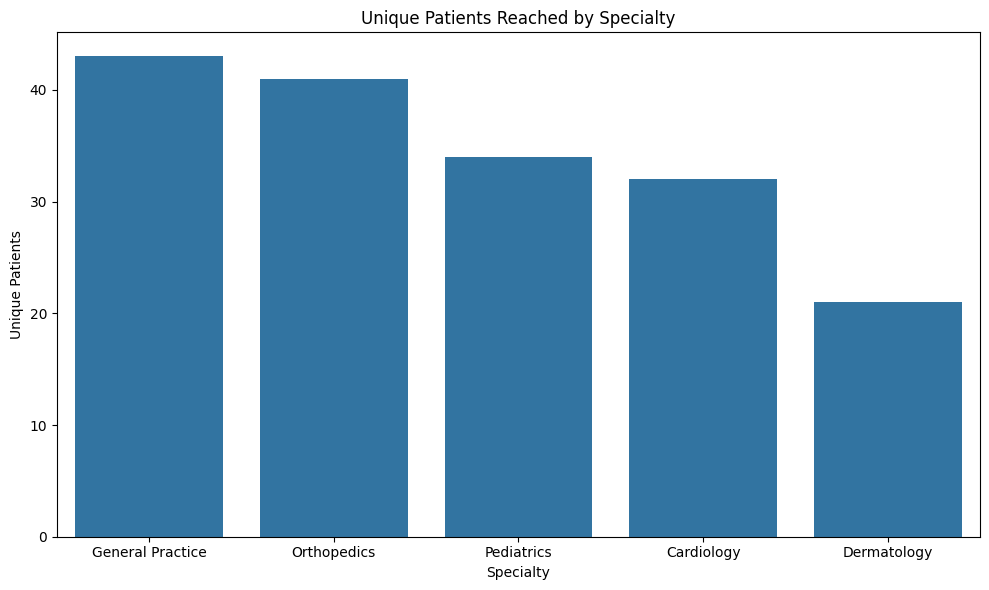

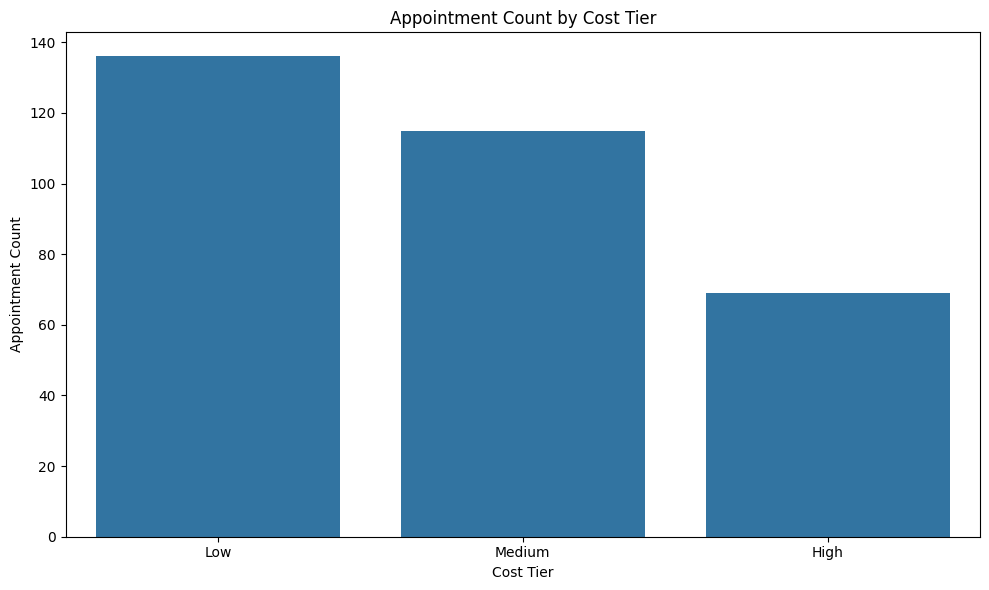

In [56]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: unique patients reached by specialty (bar)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='specialty', y='unique_patients', data=patient_specialty_counts, ax=ax)
ax.set_title('Unique Patients Reached by Specialty')
ax.set_xlabel('Specialty')
ax.set_ylabel('Unique Patients')
plt.tight_layout()

# Chart 2: appointment count by cost tier (bar)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='cost_tier', y='tier_count', data=tier_counts, ax=ax)
ax.set_title('Appointment Count by Cost Tier')
ax.set_xlabel('Cost Tier')
ax.set_ylabel('Appointment Count')
plt.tight_layout()


---
# 💼 Business Insights
*What did I discover?*

- General Practice reaches **43** patients. Dermatology reaches **21**.  
  (고유 환자 1위는 General Practice 43명. Dermatology는 21명)
- **25** patients are above the **5.42** visit average. Rachel Cooper has **15** visits.  
  (평균 5.42회보다 많이 방문한 환자는 25명. Rachel Cooper는 15회)
- Low holds **136** of **320** appointments, which is **42.5%**. High holds **69**.  
  (Low가 320건 중 136건으로 42.5%. High는 69건)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Dermatology reaches **21** patients, **22** fewer than General Practice at **43**.  
   (Dermatology 도달은 21명으로 General Practice 43명보다 22명 적음)
2. Keep the **25** patients above **5.42** visits in view. Rachel Cooper has **15**.  
   (평균 5.42회보다 많이 온 환자 25명을 같이 볼 것. Rachel Cooper는 15회)
3. Low is **42.5%** of appointments. High is **69** appointments, **21.6%**.  
   (Low가 진료의 42.5%. High는 69건으로 21.6%)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- The first average subquery selected `FROM patient_visit_counts` inside another query. That name exists only in the outer `FROM`.  
  (첫 평균 서브쿼리가 다른 쿼리 안에서 `FROM patient_visit_counts`를 썼음. 그 이름은 바깥 `FROM`에만 있음)
- The numerator was easy to swap with `COUNT(DISTINCT patient_id)`. The visit total is `COUNT(*)`.  
  (분자를 `COUNT(DISTINCT patient_id)`와 바꾸기 쉬웠음. 방문 합계는 `COUNT(*)`)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `JOIN` patients, appointments, and doctors, then `COUNT(DISTINCT patient_id)` by specialty.  
  (patients, appointments, doctors를 `JOIN`한 뒤 과목별로 `COUNT(DISTINCT patient_id)`)
- The average visit count is `COUNT(*) * 1.0 / COUNT(DISTINCT patient_id)`. `HAVING` keeps groups above that subquery.  
  (평균 방문 횟수는 `COUNT(*) * 1.0 / COUNT(DISTINCT patient_id)`. 그 서브쿼리보다 큰 그룹은 `HAVING`이 남김)
- `CASE WHEN` buckets cost into Low below **$60**, Medium from **$60** to **$100**, and High above **$100**.  
  (`CASE WHEN`은 비용을 Low $60 미만, Medium $60~$100, High $100 초과로 나눔)  

---
# 🧠 Reflection

**What was difficult?**  
Setting the average visit count in the subquery.  
(서브쿼리에서 평균 방문 횟수를 정하는 것)

**Why?**  
`COUNT(DISTINCT patient_id)` is the number of patients, so it belongs in the denominator. `COUNT(*)` is the visit total.  
(`COUNT(DISTINCT patient_id)`는 환자 수라서 분모에 둠. `COUNT(*)`가 방문 합계)

**How did I solve it?**  
Compared each patient's `COUNT(appointment_id)` with `COUNT(*) * 1.0 / COUNT(DISTINCT patient_id)` in `HAVING`.  
(환자별 `COUNT(appointment_id)`를 `HAVING`에서 `COUNT(*) * 1.0 / COUNT(DISTINCT patient_id)`와 비교함)

**What would I do differently next time?**  
Write the average as total visits divided by patients before choosing the two `COUNT` calls.  
(두 `COUNT`를 고르기 전에 평균을 방문 합계 나누기 환자 수로 적어 두기)

---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
The three queries match the questions. General Practice reaches **43** patients, **25** patients are above **5.42** visits, and Low has **136** appointments.  
(쿼리 세 개는 질문과 맞음. General Practice 43명, 평균 5.42회 초과는 25명, Low는 136건)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
The joins and the cost tiers were short. The hard part was the average subquery.  
(조인과 비용 구간은 짧았음. 어려운 부분은 평균 서브쿼리였음)

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 51 — visualization storytelling with Seaborn (Round 4/5)  
  (Seaborn으로 차트에 설명을 붙여 하나의 이야기를 만들기)  